In [1]:
import pandas as pd
import numpy as np

pd.set_option('display.max_columns', None) 
pd.set_option('display.width', None)              # don't limit the line width
pd.set_option('display.expand_frame_repr', False) # keep each row on one line instead of wrapping
pd.set_option('display.max_colwidth', None)    


In [28]:


df = pd.read_parquet("../data/yellow_taxi/raw/yellow_tripdata_2025-01.parquet")

In [4]:
df.describe()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
count,3.475226e+06,3475226,3475226,2.935077e+06,3.475226e+06,2.935077e+06,3.475226e+06,3.475226e+06,3.475226e+06,3.475226e+06,3.475226e+06,3.475226e+06,3.475226e+06,3.475226e+06,3.475226e+06,3.475226e+06,2.935077e+06,2.935077e+06,3.475226e+06
mean,1.785428e+00,2025-01-17 11:02:55.910964,2025-01-17 11:17:56.997901,1.297859e+00,5.855126e+00,2.482535e+00,1.651916e+02,1.641252e+02,1.036623e+00,1.708180e+01,1.317737e+00,4.780991e-01,2.959813e+00,4.493081e-01,9.547946e-01,2.561129e+01,2.225237e+00,1.239111e-01,4.834093e-01
min,1.000000e+00,2024-12-31 20:47:55,2024-12-18 07:52:40,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,-9.000000e+02,-7.500000e+00,-5.000000e-01,-8.600000e+01,-1.269400e+02,-1.000000e+00,-9.010000e+02,-2.500000e+00,-1.750000e+00,-7.500000e-01
25%,2.000000e+00,2025-01-10 07:59:01,2025-01-10 08:15:29.500000,1.000000e+00,9.800000e-01,1.000000e+00,1.320000e+02,1.130000e+02,1.000000e+00,8.600000e+00,0.000000e+00,5.000000e-01,0.000000e+00,0.000000e+00,1.000000e+00,1.520000e+01,2.500000e+00,0.000000e+00,0.000000e+00
50%,2.000000e+00,2025-01-17 15:41:33,2025-01-17 15:59:34,1.000000e+00,1.670000e+00,1.000000e+00,1.620000e+02,1.620000e+02,1.000000e+00,1.211000e+01,0.000000e+00,5.000000e-01,2.450000e+00,0.000000e+00,1.000000e+00,1.995000e+01,2.500000e+00,0.000000e+00,7.500000e-01
75%,2.000000e+00,2025-01-24 19:34:06,2025-01-24 19:48:31,1.000000e+00,3.100000e+00,1.000000e+00,2.340000e+02,2.340000e+02,1.000000e+00,1.950000e+01,2.500000e+00,5.000000e-01,3.930000e+00,0.000000e+00,1.000000e+00,2.778000e+01,2.500000e+00,0.000000e+00,7.500000e-01
max,7.000000e+00,2025-02-01 00:00:44,2025-02-01 23:44:11,9.000000e+00,2.764236e+05,9.900000e+01,2.650000e+02,2.650000e+02,5.000000e+00,8.633721e+05,1.500000e+01,1.050000e+01,4.000000e+02,1.709400e+02,1.000000e+00,8.633804e+05,2.500000e+00,6.750000e+00,7.500000e-01
std,4.263282e-01,NaN,NaN,7.507503e-01,5.646016e+02,1.163277e+01,6.452948e+01,6.940169e+01,7.013334e-01,4.634729e+02,1.861509e+00,1.374623e-01,3.779681e+00,2.002582e+00,2.781938e-01,4.636585e+02,9.039932e-01,4.725090e-01,3.619307e-01


In [5]:
df.shape


(3475226, 20)

In [6]:
df.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
0,1,2025-01-01 00:18:38,2025-01-01 00:26:59,1.0,1.60,1.0,N,229,237,1,10.0,3.5,0.5,3.00,0.0,1.0,18.00,2.5,0.0,0.0
1,1,2025-01-01 00:32:40,2025-01-01 00:35:13,1.0,0.50,1.0,N,236,237,1,5.1,3.5,0.5,2.02,0.0,1.0,12.12,2.5,0.0,0.0
2,1,2025-01-01 00:44:04,2025-01-01 00:46:01,1.0,0.60,1.0,N,141,141,1,5.1,3.5,0.5,2.00,0.0,1.0,12.10,2.5,0.0,0.0
3,2,2025-01-01 00:14:27,2025-01-01 00:20:01,3.0,0.52,1.0,N,244,244,2,7.2,1.0,0.5,0.00,0.0,1.0,9.70,0.0,0.0,0.0
4,2,2025-01-01 00:21:34,2025-01-01 00:25:06,3.0,0.66,1.0,N,244,116,2,5.8,1.0,0.5,0.00,0.0,1.0,8.30,0.0,0.0,0.0


In [8]:

df.dtypes


VendorID                          int32
tpep_pickup_datetime     datetime64[us]
tpep_dropoff_datetime    datetime64[us]
passenger_count                 float64
trip_distance                   float64
RatecodeID                      float64
store_and_fwd_flag                  str
PULocationID                      int32
DOLocationID                      int32
payment_type                      int64
fare_amount                     float64
extra                           float64
mta_tax                         float64
tip_amount                      float64
tolls_amount                    float64
improvement_surcharge           float64
total_amount                    float64
congestion_surcharge            float64
Airport_fee                     float64
cbd_congestion_fee              float64
dtype: object

In [29]:
df["duration"] = (df.tpep_dropoff_datetime - df.tpep_pickup_datetime).dt.total_seconds() / 60

In [30]:
required_columns = ["tpep_pickup_datetime","tpep_dropoff_datetime", "passenger_count", "trip_distance", "PULocationID", "DOLocationID"]
analysis_columns = ["tpep_pickup_datetime","tpep_dropoff_datetime", "passenger_count", "trip_distance", "PULocationID", "DOLocationID", "duration","fare_amount", "tip_amount", "total_amount"]
req_df = df[required_columns]
req_df.describe()

,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,PULocationID,DOLocationID
count,3475226,3475226,2.935077e+06,3.475226e+06,3.475226e+06,3.475226e+06
mean,2025-01-17 11:02:55.910964,2025-01-17 11:17:56.997901,1.297859e+00,5.855126e+00,1.651916e+02,1.641252e+02
min,2024-12-31 20:47:55,2024-12-18 07:52:40,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00
25%,2025-01-10 07:59:01,2025-01-10 08:15:29.500000,1.000000e+00,9.800000e-01,1.320000e+02,1.130000e+02
50%,2025-01-17 15:41:33,2025-01-17 15:59:34,1.000000e+00,1.670000e+00,1.620000e+02,1.620000e+02
75%,2025-01-24 19:34:06,2025-01-24 19:48:31,1.000000e+00,3.100000e+00,2.340000e+02,2.340000e+02
max,2025-02-01 00:00:44,2025-02-01 23:44:11,9.000000e+00,2.764236e+05,2.650000e+02,2.650000e+02
std,NaN,NaN,7.507503e-01,5.646016e+02,6.452948e+01,6.940169e+01


In [31]:
analysis_df = df[analysis_columns]
analysis_df.columns = ["pickup_datetime","dropoff_datetime", "passenger_count", "trip_distance", "PULocationID", "DOLocationID", "duration","fare_amount", "tip_amount", "total_amount"]
analysis_df.describe()


,pickup_datetime,dropoff_datetime,passenger_count,trip_distance,PULocationID,DOLocationID,duration,fare_amount,tip_amount,total_amount
count,3475226,3475226,2.935077e+06,3.475226e+06,3.475226e+06,3.475226e+06,3.475226e+06,3.475226e+06,3.475226e+06,3.475226e+06
mean,2025-01-17 11:02:55.910964,2025-01-17 11:17:56.997901,1.297859e+00,5.855126e+00,1.651916e+02,1.641252e+02,1.501812e+01,1.708180e+01,2.959813e+00,2.561129e+01
min,2024-12-31 20:47:55,2024-12-18 07:52:40,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,-5.147232e+04,-9.000000e+02,-8.600000e+01,-9.010000e+02
25%,2025-01-10 07:59:01,2025-01-10 08:15:29.500000,1.000000e+00,9.800000e-01,1.320000e+02,1.130000e+02,7.283333e+00,8.600000e+00,0.000000e+00,1.520000e+01
50%,2025-01-17 15:41:33,2025-01-17 15:59:34,1.000000e+00,1.670000e+00,1.620000e+02,1.620000e+02,1.170000e+01,1.211000e+01,2.450000e+00,1.995000e+01
75%,2025-01-24 19:34:06,2025-01-24 19:48:31,1.000000e+00,3.100000e+00,2.340000e+02,2.340000e+02,1.833333e+01,1.950000e+01,3.930000e+00,2.778000e+01
max,2025-02-01 00:00:44,2025-02-01 23:44:11,9.000000e+00,2.764236e+05,2.650000e+02,2.650000e+02,5.626317e+03,8.633721e+05,4.000000e+02,8.633804e+05
std,NaN,NaN,7.507503e-01,5.646016e+02,6.452948e+01,6.940169e+01,3.871358e+01,4.634729e+02,3.779681e+00,4.636585e+02


In [12]:
analysis_df.shape

(3475226, 10)

In [32]:
df_a = analysis_df[analysis_df["pickup_datetime"]  > analysis_df["dropoff_datetime"]]
df_a.shape

df_a.head(20)


,pickup_datetime,dropoff_datetime,passenger_count,trip_distance,PULocationID,DOLocationID,duration,fare_amount,tip_amount,total_amount
99620,2025-01-02 12:26:00,2025-01-02 11:29:58,1.0,9.00,88,210,-56.033333,45.50,0.0,46.00
459885,2025-01-06 16:00:00,2025-01-06 15:05:30,1.0,3.80,208,254,-54.500000,24.50,0.0,25.00
1315880,2025-01-15 15:00:00,2025-01-15 14:42:48,1.0,1.00,107,4,-17.200000,18.50,0.0,19.00
2029534,2025-01-23 01:44:59,2024-12-18 07:52:40,0.0,3.10,162,238,-51472.316667,21.90,4.5,30.40
2058555,2025-01-23 12:30:00,2025-01-23 11:44:59,1.0,3.90,236,116,-45.016667,27.50,0.0,28.00
2660983,2025-01-29 14:00:00,2025-01-29 13:30:15,1.0,1.50,72,222,-29.750000,19.50,0.0,20.00
2945475,2025-01-01 10:01:27,2025-01-01 10:01:00,NaN,19.19,169,35,-0.450000,2.90,0.0,68.77
2945514,2025-01-01 10:01:53,2025-01-01 10:01:33,NaN,12.17,41,121,-0.333333,1.45,0.0,35.87
2951588,2025-01-02 08:01:41,2025-01-02 08:01:16,NaN,14.89,28,244,-0.416667,2.90,0.0,39.11
2952145,2025-01-02 11:01:37,2025-01-02 11:01:29,NaN,12.71,197,74,-0.133333,2.90,0.0,34.86


In [19]:
is_jan = (analysis_df['pickup_datetime'].dt.year == 2025) & (analysis_df['pickup_datetime'].dt.month == 1)
outside_jan = analysis_df[~is_jan]
outside_jan.shape
m_outside_jan = outside_jan.shape[0]
pct_outside_jan = (outside_jan.shape[0] / analysis_df.shape[0]) * 100
print(f"Number of records outside January 2025: {m_outside_jan}")
print(f"Percentage of records outside January 2025: {pct_outside_jan:.4f}%")
outside_jan.head(22)

Number of records outside January 2025: 22
Percentage of records outside January 2025: 0.0006%


,pickup_datetime,dropoff_datetime,passenger_count,trip_distance,PULocationID,DOLocationID,duration,fare_amount,tip_amount,total_amount
605,2024-12-31 23:30:03,2024-12-31 23:43:02,1.0,3.00,246,13,12.983333,16.3,5.32,26.62
687,2024-12-31 23:31:38,2024-12-31 23:41:48,1.0,1.03,43,140,10.166667,10.7,0.00,15.70
688,2024-12-31 23:46:38,2025-01-01 00:03:03,1.0,3.95,229,24,16.416667,19.1,0.00,24.10
861,2024-12-31 23:56:19,2025-01-01 00:11:19,6.0,2.28,68,107,15.000000,14.9,3.98,23.88
1108,2024-12-31 23:55:37,2025-01-01 00:01:26,1.0,1.12,56,56,5.816667,7.9,0.00,10.40
1312,2024-12-31 23:52:40,2025-01-01 00:23:03,1.0,6.72,114,151,30.383333,34.5,7.90,47.40
2276,2024-12-31 23:49:24,2024-12-31 23:57:30,1.0,2.44,142,151,8.100000,12.1,3.42,20.52
3941,2024-12-31 23:27:13,2024-12-31 23:35:48,1.0,1.53,170,141,8.583333,10.0,3.00,18.00
3942,2024-12-31 23:37:42,2024-12-31 23:43:10,1.0,0.92,229,141,5.466667,7.2,1.83,14.03
4324,2024-12-31 23:51:20,2025-01-01 00:00:00,1.0,12.89,138,40,8.666667,48.5,11.55,69.30


In [34]:
jan_2025_df = analysis_df[is_jan]
jan_2025_df.shape

(3475204, 10)

In [38]:
is_pickup_gt_dropoff = jan_2025_df['pickup_datetime'] > jan_2025_df['dropoff_datetime']
jan_2025_df[is_pickup_gt_dropoff].shape
m_pickup_gt_dropoff = jan_2025_df[is_pickup_gt_dropoff].shape[0]
pct_pickup_gt_dropoff = (m_pickup_gt_dropoff / jan_2025_df.shape[0]) * 100
print(f"Number of records with pickup_datetime greater than dropoff_datetime: {m_pickup_gt_dropoff}")
print(f"Percentage of records with pickup_datetime greater than dropoff_datetime: {pct_pickup_gt_dropoff:.4f}%")


Number of records with pickup_datetime greater than dropoff_datetime: 124
Percentage of records with pickup_datetime greater than dropoff_datetime: 0.0036%


In [39]:
jan_2025_df_valid = jan_2025_df[~is_pickup_gt_dropoff]
jan_2025_df_valid.shape

(3475080, 10)

In [41]:
jan_2025_df_valid.describe()

,pickup_datetime,dropoff_datetime,passenger_count,trip_distance,PULocationID,DOLocationID,duration,fare_amount,tip_amount,total_amount
count,3475080,3475080,2.935049e+06,3.475080e+06,3.475080e+06,3.475080e+06,3.475080e+06,3.475080e+06,3.475080e+06,3.475080e+06
mean,2025-01-17 11:03:06.940387,2025-01-17 11:18:08.951984,1.297856e+00,5.855124e+00,1.651929e+02,1.641270e+02,1.503353e+01,1.708226e+01,2.959909e+00,2.561130e+01
min,2025-01-01 00:00:00,2025-01-01 00:00:00,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,-9.000000e+02,-8.600000e+01,-9.010000e+02
25%,2025-01-10 07:59:14,2025-01-10 08:15:47.500000,1.000000e+00,9.800000e-01,1.320000e+02,1.130000e+02,7.283333e+00,8.600000e+00,0.000000e+00,1.520000e+01
50%,2025-01-17 15:41:46,2025-01-17 15:59:46.500000,1.000000e+00,1.670000e+00,1.620000e+02,1.620000e+02,1.170000e+01,1.211000e+01,2.450000e+00,1.995000e+01
75%,2025-01-24 19:34:11,2025-01-24 19:48:35,1.000000e+00,3.100000e+00,2.340000e+02,2.340000e+02,1.833333e+01,1.950000e+01,3.930000e+00,2.778000e+01
max,2025-01-31 23:59:59,2025-02-01 23:44:11,9.000000e+00,2.764236e+05,2.650000e+02,2.650000e+02,5.626317e+03,8.633721e+05,4.000000e+02,8.633804e+05
std,NaN,NaN,7.507412e-01,5.646135e+02,6.452886e+01,6.940088e+01,2.712829e+01,4.634826e+02,3.779701e+00,4.636682e+02


In [45]:
min_duration = jan_2025_df_valid['duration'].min()
max_duration = jan_2025_df_valid['duration'].max()  
mean_duration = jan_2025_df_valid['duration'].mean()    
print(f"Minimum duration: {min_duration} minutes")
print(f"Maximum duration: {max_duration} minutes")
print(f"Mean duration: {mean_duration:.2f} minutes")
mode_duration = jan_2025_df_valid['duration'].mode()[0]
print(f"Mode duration: {mode_duration} minutes")
median_duration = jan_2025_df_valid['duration'].median()
print(f"Median duration: {median_duration} minutes")

Minimum duration: 0.0 minutes
Maximum duration: 5626.316666666667 minutes
Mean duration: 15.03 minutes
Mode duration: 9.0 minutes
Median duration: 11.7 minutes


In [61]:
key = ["pickup_datetime", "dropoff_datetime", "PULocationID", "DOLocationID"]
dupes = jan_2025_df_valid[jan_2025_df_valid.duplicated(key, keep=False)].sort_values(key)
dupes[key + ["fare_amount", "total_amount","tip_amount"]].head(10)


#dupes.shape

,pickup_datetime,dropoff_datetime,PULocationID,DOLocationID,fare_amount,total_amount,tip_amount
5515,2025-01-01 00:00:07,2025-01-01 00:06:31,148,45,-7.9,-12.90,0.00
5516,2025-01-01 00:00:07,2025-01-01 00:06:31,148,45,7.9,12.90,0.00
4531,2025-01-01 00:01:19,2025-01-01 00:01:38,164,164,0.0,-2.50,0.00
4532,2025-01-01 00:01:19,2025-01-01 00:01:38,164,164,0.0,2.50,0.00
17,2025-01-01 00:01:41,2025-01-01 00:07:14,79,107,-7.2,-8.54,3.66
18,2025-01-01 00:01:41,2025-01-01 00:07:14,79,107,7.2,12.20,0.00
3350,2025-01-01 00:02:03,2025-01-01 00:09:42,161,162,-7.9,-12.90,0.00
3351,2025-01-01 00:02:03,2025-01-01 00:09:42,161,162,7.9,12.90,0.00
1805,2025-01-01 00:02:08,2025-01-01 00:13:45,234,125,-13.5,-18.50,0.00
1806,2025-01-01 00:02:08,2025-01-01 00:13:45,234,125,13.5,18.50,0.00


In [60]:
is_fare_equal_total = dupes["fare_amount"] == dupes["total_amount"]
n_fare_equal_total = is_fare_equal_total.sum()
print(f"Number of duplicate records with fare_amount equal to total_amount: {n_fare_equal_total}")

Number of duplicate records with fare_amount equal to total_amount: 7


In [62]:
is_valid_amounts =  jan_2025_df_valid["total_amount"] >= 0
jan_2025_df_valid_amounts = jan_2025_df_valid[is_valid_amounts]
jan_2025_df_valid_amounts.shape

(3412043, 10)

In [67]:
duration_gt_500 = jan_2025_df_valid_amounts[jan_2025_df_valid_amounts['duration'] > 500]
duration_gt_500.shape
n_duration_gt_500 = duration_gt_500.shape[0]
pct_duration_gt_500 = (n_duration_gt_500 / jan_2025_df_valid_amounts.shape[0]) * 100
print(f"Number of records with duration greater than 500 minutes: {n_duration_gt_500}")
print(f"Percentage of records with duration greater than 500 minutes: {pct_duration_gt_500:.4f}%")  
duration_gt_500[["duration", "trip_distance", "PULocationID", "DOLocationID"]].describe()
   # in hours

Number of records with duration greater than 500 minutes: 1114
Percentage of records with duration greater than 500 minutes: 0.0326%


,duration,trip_distance,PULocationID,DOLocationID
count,1114.000000,1114.000000,1114.000000,1114.000000
mean,1321.976391,5.038321,164.469479,162.657989
std,347.233291,12.763115,62.360957,70.016753
min,501.583333,0.000000,4.000000,1.000000
25%,1385.045833,1.160000,132.000000,113.000000
50%,1413.916667,2.005000,161.000000,162.000000
75%,1431.662500,5.117500,231.000000,232.000000
max,5626.316667,265.900000,265.000000,265.000000


In [70]:
duration_gt_200 = jan_2025_df_valid_amounts[jan_2025_df_valid_amounts['duration'] > 200]
duration_gt_200.shape
n_duration_gt_200 = duration_gt_200.shape[0]
pct_duration_gt_200 = (n_duration_gt_200 / jan_2025_df_valid_amounts.shape[0]) * 100
print(f"Number of records with duration greater than 200 minutes: {n_duration_gt_200}")
print(f"Percentage of records with duration greater than 200 minutes: {pct_duration_gt_200:.4f}%")  
duration_gt_200[["duration", "trip_distance", "PULocationID", "DOLocationID"]].describe()
   # in hours

Number of records with duration greater than 200 minutes: 1325
Percentage of records with duration greater than 200 minutes: 0.0388%


,duration,trip_distance,PULocationID,DOLocationID
count,1325.000000,1325.000000,1325.000000,1325.000000
mean,1162.190126,6.644785,161.748679,158.692830
std,487.439971,16.013320,62.534482,70.604607
min,200.383333,0.000000,4.000000,1.000000
25%,820.783333,1.220000,132.000000,107.000000
50%,1403.850000,2.300000,161.000000,161.000000
75%,1429.266667,7.620000,230.000000,231.000000
max,5626.316667,265.900000,265.000000,265.000000


In [71]:
duration_gt_150 = jan_2025_df_valid_amounts[jan_2025_df_valid_amounts['duration'] > 150]
duration_gt_150.shape
n_duration_gt_150 = duration_gt_150.shape[0]
pct_duration_gt_150 = (n_duration_gt_150 / jan_2025_df_valid_amounts.shape[0]) * 100
print(f"Number of records with duration greater than 150 minutes: {n_duration_gt_150}")
print(f"Percentage of records with duration greater than 150 minutes: {pct_duration_gt_150:.4f}%")  
duration_gt_150[["duration", "trip_distance", "PULocationID", "DOLocationID"]].describe()
   # in hours

Number of records with duration greater than 150 minutes: 1495
Percentage of records with duration greater than 150 minutes: 0.0438%


,duration,trip_distance,PULocationID,DOLocationID
count,1495.000000,1495.000000,1495.000000,1495.000000
mean,1049.212609,8.661371,159.890301,157.824080
std,556.893949,19.963811,63.463373,71.324957
min,150.033333,0.000000,4.000000,1.000000
25%,480.375000,1.265000,132.000000,107.000000
50%,1395.366667,2.660000,157.000000,161.000000
75%,1426.933333,9.710000,230.000000,230.000000
max,5626.316667,265.900000,265.000000,265.000000


In [ ]:
duration_gt_500_trip_200 = duration_gt_500[duration_gt_500['trip_distance'] > 200]
duration_gt_500_trip_200.shape

(2, 10)

In [68]:
(duration_gt_500["duration"] / 60).round().value_counts().head() 

duration
24.0    587
23.0    276
22.0     29
11.0     26
14.0     22
Name: count, dtype: int64

In [74]:
duration_gt_200_trip_200 = duration_gt_200[duration_gt_200['trip_distance'] > 100]
duration_gt_200_trip_200.shape

(5, 10)

In [75]:
(duration_gt_200["duration"] / 60).round().value_counts().head() 

duration
24.0    587
23.0    276
4.0      61
5.0      41
8.0      39
Name: count, dtype: int64

In [48]:
jan_2025_df_valid.sort_values(by='duration', ascending=False).head(20)

,pickup_datetime,dropoff_datetime,passenger_count,trip_distance,PULocationID,DOLocationID,duration,fare_amount,tip_amount,total_amount
1858817,2025-01-21 12:23:41,2025-01-25 10:10:00,1.0,6.55,70,129,5626.316667,28.20,0.0,36.45
1858816,2025-01-21 12:23:41,2025-01-25 10:10:00,1.0,6.55,70,70,5626.316667,-28.20,0.0,-36.45
414374,2025-01-06 02:12:11,2025-01-09 13:54:19,1.0,91.51,218,193,5022.133333,336.90,0.0,339.40
2460536,2025-01-27 11:58:55,2025-01-30 09:42:55,1.0,0.00,207,226,4184.000000,3.00,0.0,4.50
898201,2025-01-11 08:04:00,2025-01-13 16:49:28,1.0,0.04,132,226,3405.466667,70.00,0.0,76.50
2147536,2025-01-24 07:07:21,2025-01-26 10:09:44,1.0,0.00,207,142,3062.383333,3.00,0.0,4.50
85681,2025-01-02 09:40:31,2025-01-04 09:37:01,1.0,0.00,193,181,2876.500000,3.00,0.0,4.50
1536147,2025-01-17 16:45:49,2025-01-19 16:40:59,1.0,1.98,229,265,2875.166667,12.80,0.0,20.05
556772,2025-01-07 18:07:33,2025-01-09 16:12:05,1.0,1.86,265,141,2764.533333,47.80,0.0,51.80
3417048,2025-01-29 21:39:23,2025-01-31 16:48:43,NaN,7.52,231,193,2589.333333,31.02,0.0,35.77


In [43]:
neg_fare_amount_df = jan_2025_df_valid[jan_2025_df_valid["fare_amount"] < 0]
neg_fare_amount_df.shape
neg_fare_amount_df.head(20)

,pickup_datetime,dropoff_datetime,passenger_count,trip_distance,PULocationID,DOLocationID,duration,fare_amount,tip_amount,total_amount
17,2025-01-01 00:01:41,2025-01-01 00:07:14,1.0,0.71,79,107,5.550000,-7.2,3.66,-8.54
22,2025-01-01 00:55:54,2025-01-01 01:00:38,1.0,0.69,137,233,4.733333,-6.5,0.00,-11.50
104,2025-01-01 00:56:12,2025-01-01 01:15:00,1.0,0.97,161,170,18.800000,-16.3,0.00,-21.30
149,2025-01-01 00:55:53,2025-01-01 01:06:49,1.0,1.42,79,45,10.933333,-12.1,0.00,-17.10
202,2025-01-01 00:29:35,2025-01-01 00:36:02,1.0,0.60,79,148,6.450000,-7.2,0.00,-12.20
212,2025-01-01 00:11:44,2025-01-01 00:25:41,2.0,1.88,79,161,13.950000,-14.2,0.00,-19.20
364,2025-01-01 00:11:58,2025-01-01 00:12:31,1.0,0.01,42,42,0.550000,-3.0,0.00,-5.50
400,2025-01-01 00:09:58,2025-01-01 00:14:28,1.0,0.60,140,263,4.500000,-6.5,0.00,-11.50
492,2025-01-01 00:50:13,2025-01-01 01:11:20,1.0,3.84,48,151,21.116667,-24.0,0.00,-29.00
640,2025-01-01 00:51:05,2025-01-01 00:54:12,1.0,0.92,142,239,3.116667,-6.5,0.00,-11.50


In [58]:
trip_distance_0 = df[df["trip_distance"] == 0]
count_0 = len(trip_distance_0)
print(f"Number of rows with trip_distance = 0: {count_0}")
print(trip_distance_0.select(analysis_columns).head(10))

Number of rows with trip_distance = 0: 90893
     tpep_pickup_datetime tpep_dropoff_datetime  passenger_count  trip_distance  PULocationID  DOLocationID   duration  fare_amount  tip_amount  total_amount
92    2025-01-01 00:49:48   2025-01-01 00:49:48              1.0            0.0            87           264   0.000000        20.06        0.00         20.06
204   2025-01-01 00:37:43   2025-01-01 00:37:53              1.0            0.0           148           148   0.166667        12.00        2.00         17.50
358   2025-01-01 00:57:08   2025-01-01 00:57:16              3.0            0.0           141           141   0.133333        30.00        0.00         33.50
505   2025-01-01 00:27:40   2025-01-01 00:59:30              1.0            0.0           168            76  31.833333        50.50        0.00         58.94
619   2025-01-01 00:56:49   2025-01-01 00:56:54              4.0            0.0           164           164   0.083333        20.00        7.05         30.55
706   2

In [10]:
df.isna().sum().sort_values(ascending=False)

passenger_count          540149
congestion_surcharge     540149
store_and_fwd_flag       540149
RatecodeID               540149
Airport_fee              540149
tpep_dropoff_datetime         0
VendorID                      0
tpep_pickup_datetime          0
DOLocationID                  0
payment_type                  0
trip_distance                 0
PULocationID                  0
extra                         0
fare_amount                   0
mta_tax                       0
tip_amount                    0
improvement_surcharge         0
tolls_amount                  0
total_amount                  0
cbd_congestion_fee            0
dtype: int64

In [76]:
pct = jan_2025_df_valid_amounts["duration"].quantile([0, .001, .01, .05, .25, .5, .75, .95, .99, .999, 1])
pct.round(2)

0.000       0.00
0.001       0.07
0.010       1.05
0.050       3.43
0.250       7.32
0.500      11.72
0.750      18.35
0.950      36.12
0.990      58.88
0.999      98.37
1.000    5626.32
Name: duration, dtype: float64

<Axes: title={'center': 'Upper tail of duration'}>

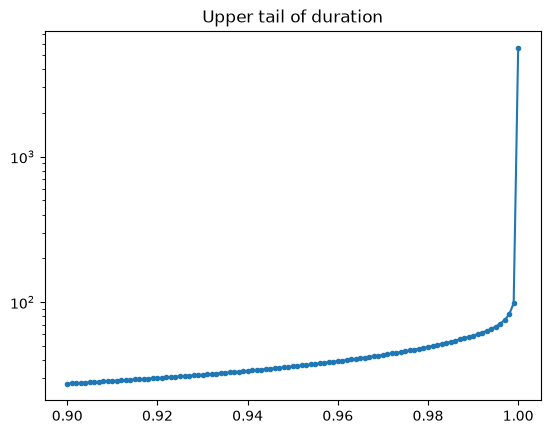

In [77]:
p = np.arange(0.90, 1.0001, 0.001)
q = jan_2025_df_valid_amounts["duration"].quantile(p)
q.plot(marker=".", logy=True, title="Upper tail of duration")

In [78]:
for lo, hi in [(0, 60), (1, 60), (1, 90), (1, 120)]:
    kept = jan_2025_df_valid_amounts["duration"].between(lo, hi).mean()
    print(f"{lo}-{hi} min: keep {kept:.2%}")

0-60 min: keep 99.09%
1-60 min: keep 98.11%
1-90 min: keep 98.89%
1-120 min: keep 98.97%


In [80]:
for lo, hi in [(0, 100), (100, 200), (200, 300)]:
    kept = df["trip_distance"].between(lo, hi).mean()
    print(f"{lo}-{hi} min: keep {kept:.2%}")

0-100 min: keep 100.00%
100-200 min: keep 0.00%
200-300 min: keep 0.00%


In [81]:
df["speed"] = df["trip_distance"] / df["duration"]
for lo, hi in [(0, 50), (50, 100), (100, 300)]:
    kept = df["speed"].between(lo, hi).mean()
    print(f"{lo}-{hi} speed: keep {kept:.2%}")

0-50 speed: keep 99.93%
50-100 speed: keep 0.00%
100-300 speed: keep 0.00%


In [85]:
jan_2025_df_valid_amounts[jan_2025_df_valid_amounts["duration"] == 0].head(20)

,pickup_datetime,dropoff_datetime,passenger_count,trip_distance,PULocationID,DOLocationID,duration,fare_amount,tip_amount,total_amount
92,2025-01-01 00:49:48,2025-01-01 00:49:48,1.0,0.00,87,264,0.0,20.06,0.00,20.06
11604,2025-01-01 01:42:36,2025-01-01 01:42:36,1.0,0.00,158,264,0.0,3.00,0.00,8.00
13820,2025-01-01 02:13:25,2025-01-01 02:13:25,1.0,0.00,233,264,0.0,114.00,0.00,114.00
14605,2025-01-01 02:09:52,2025-01-01 02:09:52,1.0,0.00,237,264,0.0,3.00,0.00,8.00
14607,2025-01-01 02:49:40,2025-01-01 02:49:40,1.0,0.00,162,264,0.0,3.00,0.00,8.00
16093,2025-01-01 02:21:20,2025-01-01 02:21:20,2.0,0.00,164,264,0.0,16.30,0.00,21.30
19599,2025-01-01 03:46:16,2025-01-01 03:46:16,1.0,0.00,36,264,0.0,31.91,0.00,31.91
31891,2025-01-01 12:44:07,2025-01-01 12:44:07,2.0,1.56,143,230,0.0,17.00,10.00,31.00
34038,2025-01-01 12:21:49,2025-01-01 12:21:49,1.0,0.00,148,264,0.0,14.20,0.00,18.20
34951,2025-01-01 12:53:45,2025-01-01 12:53:45,0.0,0.00,164,264,0.0,21.55,0.00,21.55


In [88]:
jan_2025_df_valid_amounts["week"] = jan_2025_df_valid_amounts.pickup_datetime.dt.isocalendar().week
jan_2025_df_valid_amounts.groupby("week").agg(trips=("duration", "size"),
                       median_dur=("duration", "median")
                       #median_dist=("trip_distance", "median")
                       )

,trips,median_dur
week,,
1,429557,11.883333
2,737110,11.366667
3,831996,11.616667
4,827907,11.766667
5,585473,12.150000


<Axes: xlabel='pickup_datetime'>

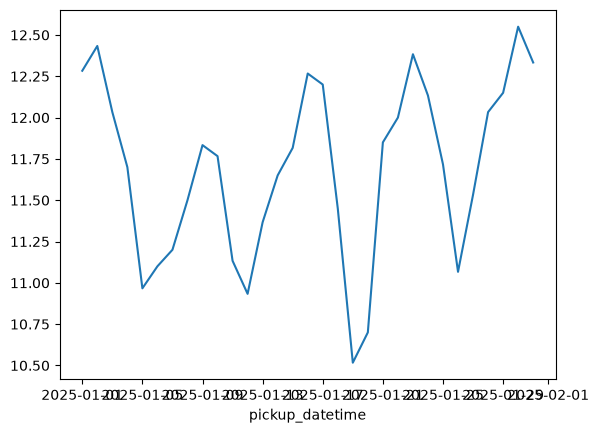

In [90]:
jan_2025_df_valid_amounts.groupby(jan_2025_df_valid_amounts.pickup_datetime.dt.date)["duration"].median().plot()